# What an expert learns, and the kinds of composition: worked examples in 2D

This notebook is the worked examples for claims 1 and 7 of [the overlap-dial idea map](IDEA_MAP.md). The definitions it illustrates are in [the composition terms](composition-terms.md).

Two questions:

1. **Does expert A care how its training points are labelled?** (claim 1: the example and the break)
2. **Are co-occurrence, intersection, contention and interaction different things, and what produces each?** (claim 7)

**No sampler appears anywhere.** In 2D, a product density can be computed exactly on a grid and normalised, so every picture below is the true target. A sampler would add its own error, which is claim 4's subject.

**What an "ideal expert" is here.** A diffusion model trained to optimum on a finite training set, at noise level $\sigma$, has the score of the training points smoothed by a Gaussian:

$$p^{\text{ideal}}_\sigma(x) = \frac{1}{N}\sum_{i=1}^{N} \mathcal{N}(x;\, x_i,\, \sigma^2 I).$$

So every expert below is that formula applied to its training set, with no network trained. This is the best any trained expert can do at noise $\sigma$, which makes every failure below a property of the data or of the composition, never of training.

In [1]:
import numpy as np, torch, matplotlib.pyplot as plt
from scipy.special import logsumexp
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 10})
rng = np.random.default_rng(0); torch.manual_seed(0)

L, G = 1.1, 241
xs = np.linspace(-L, L, G)
X1, X2 = np.meshgrid(xs, xs)
grid = np.stack([X1.ravel(), X2.ravel()], 1)
cell = (xs[1] - xs[0]) ** 2
TOP_LEFT = (X1 < 0) & (X2 > 0)           # the A∩B region in the quadrant setup

def ideal_expert(data, sigma):
    "Log-density on the grid of the training points smoothed by N(0, sigma^2 I)."
    d2 = ((grid[:, None, :] - np.asarray(data)[None]) ** 2).sum(-1)
    lp = logsumexp(-d2 / (2 * sigma**2), axis=1) - np.log(len(data)) - np.log(2 * np.pi * sigma**2)
    return lp.reshape(G, G)

def density(logp):
    "Normalise a log-density on the grid so it integrates to 1."
    p = np.exp(logp - logp.max()); return p / (p.sum() * cell)

def mass(p, region):
    return float((p * region).sum() * cell)

def show(ax, p, title, pts=None, region=TOP_LEFT):
    ax.imshow(p, origin="lower", extent=[-L, L, -L, L], cmap="magma")
    ax.axhline(0, color="w", lw=.4, alpha=.5); ax.axvline(0, color="w", lw=.4, alpha=.5)
    if pts is not None:
        ax.scatter(*np.asarray(pts).T, s=14, c="cyan", edgecolor="k", lw=.4)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])

## 1. Example: same points, different labels, same expert

Expert A's training set is three points. In **version 1** all three are labelled "A", and the top-left one is secretly also B. In **version 2** the top-left one is labelled "A, B".

The denoising loss expert A minimises is

$$\mathcal{L}(\theta) = \mathbb{E}_{x_0 \sim \text{A's set},\ t,\ \varepsilon}\ \big\| \varepsilon - \varepsilon_\theta(\sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\varepsilon,\ t) \big\|^2 .$$

**No label appears in it.** The only thing a label could change is which points are in A's set, and here it changes nothing.

largest difference between the two versions' gradients: 0.0


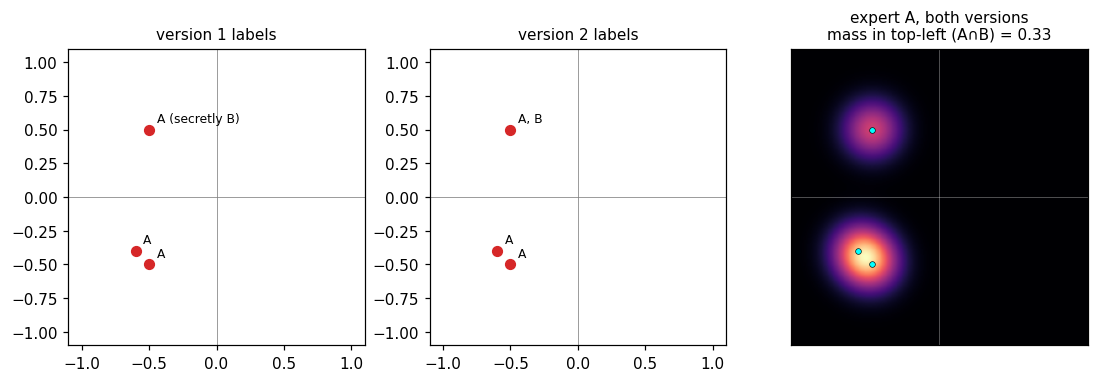

In [2]:
A_set = np.array([[-0.5, -0.5], [-0.6, -0.4], [-0.5, 0.5]])
labels_v1 = ["A", "A", "A (secretly B)"]
labels_v2 = ["A", "A", "A, B"]

# a tiny denoiser, one gradient step on each version, same seed: the labels are never an input
def one_step_grads(x0):
    torch.manual_seed(1)
    net = torch.nn.Sequential(torch.nn.Linear(3, 32), torch.nn.SiLU(), torch.nn.Linear(32, 2))
    x0 = torch.tensor(x0, dtype=torch.float32).repeat(64, 1)
    t = torch.rand(len(x0), 1); abar = torch.cos(t * torch.pi / 2) ** 2
    eps = torch.randn_like(x0)
    xt = abar.sqrt() * x0 + (1 - abar).sqrt() * eps
    loss = ((eps - net(torch.cat([xt, t], 1))) ** 2).mean()
    loss.backward()
    return torch.cat([p.grad.flatten() for p in net.parameters()])

g1, g2 = one_step_grads(A_set), one_step_grads(A_set)   # version 1 and version 2 feed the same x0
print("largest difference between the two versions' gradients:", (g1 - g2).abs().max().item())

pA = density(ideal_expert(A_set, sigma=0.15))
fig, ax = plt.subplots(1, 3, figsize=(10, 3.4))
for a, labs, name in [(ax[0], labels_v1, "version 1 labels"), (ax[1], labels_v2, "version 2 labels")]:
    a.scatter(*A_set.T, s=40, c="tab:red"); a.set_xlim(-L, L); a.set_ylim(-L, L)
    a.axhline(0, c="grey", lw=.5); a.axvline(0, c="grey", lw=.5)
    for (x, y), s in zip(A_set, labs): a.annotate(s, (x, y), (5, 5), textcoords="offset points", fontsize=8)
    a.set_title(name); a.set_aspect("equal")
show(ax[2], pA, f"expert A, both versions\nmass in top-left (A∩B) = {mass(pA, TOP_LEFT):.2f}", A_set)
plt.tight_layout()

**Reading it.** The gradient difference is exactly `0.0`, and the one heatmap serves both versions. A third of expert A's mass sits in the top-left quadrant, because one of its three points is there. **For separately trained experts (construction 2), "hidden B" and "labelled A and B" are the same experiment.**

## 2. Break, part 1: labels matter to a conditional model (construction 1)

Construction (1) trains one model on everything, conditioned on a label, and composes

$$\nabla \log p(x\mid A) + \nabla \log p(x\mid B) - \nabla \log p(x) \;=\; \nabla \log \frac{p(x\mid A)\,p(x\mid B)}{p(x)} .$$

Now the label decides which points train the condition "A". There are two readings:

- **"contains A"**: every point whose label set includes A trains $p(x\mid A)$.
- **"exactly A"**: a point labelled {A, B} trains a separate condition {A, B}, and drops out of $p(x\mid A)$.

The pool below is A's three points plus B's three points, one of which is secretly A. Version 2 labels are used throughout.

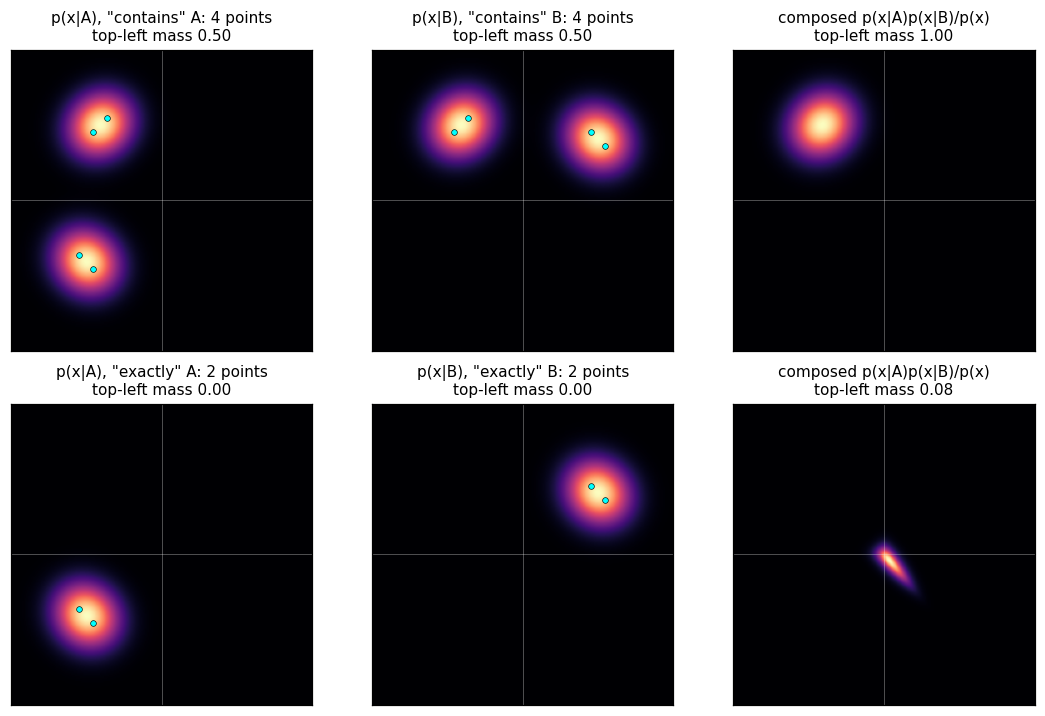

In [3]:
B_set = np.array([[0.5, 0.5], [0.6, 0.4], [-0.4, 0.6]])
pool = np.vstack([A_set, B_set])
label_sets = [{"A"}, {"A"}, {"A", "B"}, {"B"}, {"B"}, {"A", "B"}]

def condition(c, scheme):
    keep = [c in s if scheme == "contains" else s == {c} for s in label_sets]
    return pool[np.array(keep)]

sig = 0.15
lp_all = ideal_expert(pool, sig)
fig, ax = plt.subplots(2, 3, figsize=(10, 6.6))
for row, scheme in enumerate(["contains", "exactly"]):
    dA, dB = condition("A", scheme), condition("B", scheme)
    pA_c = density(ideal_expert(dA, sig)); pB_c = density(ideal_expert(dB, sig))
    comp = density(ideal_expert(dA, sig) + ideal_expert(dB, sig) - lp_all)
    show(ax[row, 0], pA_c, f'p(x|A), "{scheme}" A: {len(dA)} points\ntop-left mass {mass(pA_c, TOP_LEFT):.2f}', dA)
    show(ax[row, 1], pB_c, f'p(x|B), "{scheme}" B: {len(dB)} points\ntop-left mass {mass(pB_c, TOP_LEFT):.2f}', dB)
    show(ax[row, 2], comp, f'composed p(x|A)p(x|B)/p(x)\ntop-left mass {mass(comp, TOP_LEFT):.2f}')
plt.tight_layout()

**Reading it.** Under "contains A", the composition puts most of its mass in the top-left quadrant. Under "exactly A", the {A, B} points never train either condition, so both conditionals lose their top-left mass and the composition misses A∩B. Its leftover mass sits near the origin, between A's points and B's points, at a place no training point held. **The meaning of the condition is an axis of the experiment.** It has to be fixed and written down before the overlap dial means anything in construction (1).

## 3. Break, part 2: a classifier learns the hidden-B points as "not B"

Now a classifier $p(B\mid x)$ is trained, as in classifier guidance. Its labels come from **which set a point was in**, which is the label the data actually carries. A hidden-B point in A's set is therefore labelled "not B".

Each set has 400 points. 20% of A's set lies in the top half (hidden B), and 20% of B's set lies in the left half (hidden A). Guidance toward B adds $\nabla_x \log p(B\mid x)$ to the score. The arrows show the direction of that push (unit length, so only direction is drawn), and the title gives its average over the top-left quadrant: $(+1, 0)$ is straight right, $(0, +1)$ straight up.

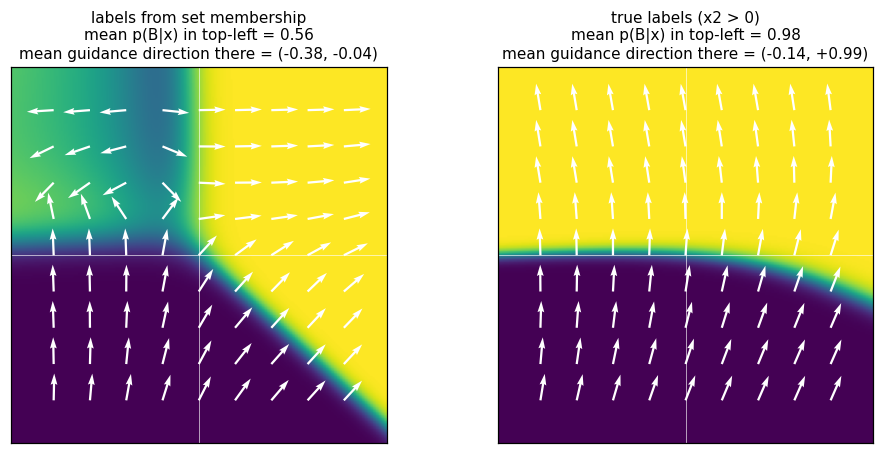

In [4]:
def make_sets(f, n=400):
    a = np.c_[rng.uniform(-1, 0, n), np.where(rng.random(n) < f, rng.uniform(0, 1, n), rng.uniform(-1, 0, n))]
    b = np.c_[np.where(rng.random(n) < f, rng.uniform(-1, 0, n), rng.uniform(0, 1, n)), rng.uniform(0, 1, n)]
    return a, b

A400, B400 = make_sets(0.2)
X = np.vstack([A400, B400])
y_from_set = np.r_[np.zeros(400), np.ones(400)]          # the label the data carries
y_true = (X[:, 1] > 0).astype(float)                       # the label the concept defines

def train_classifier(X, y, steps=1500):
    torch.manual_seed(0)
    net = torch.nn.Sequential(torch.nn.Linear(2, 64), torch.nn.SiLU(), torch.nn.Linear(64, 64), torch.nn.SiLU(), torch.nn.Linear(64, 1))
    opt = torch.optim.Adam(net.parameters(), 3e-3, weight_decay=1e-3)
    Xt, yt = torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.float32)[:, None]
    for _ in range(steps):
        opt.zero_grad(); torch.nn.functional.binary_cross_entropy_with_logits(net(Xt), yt).backward(); opt.step()
    return net

fig, ax = plt.subplots(1, 2, figsize=(9, 4.2))
q = np.linspace(-0.85, 0.85, 9); Q1, Q2 = np.meshgrid(q, q)
for a, y, name in [(ax[0], y_from_set, "labels from set membership"), (ax[1], y_true, "true labels (x2 > 0)")]:
    net = train_classifier(X, y)
    with torch.no_grad():
        pB = torch.sigmoid(net(torch.tensor(grid, dtype=torch.float32))).numpy().reshape(G, G)
    qx = torch.tensor(np.c_[Q1.ravel(), Q2.ravel()], dtype=torch.float32, requires_grad=True)
    torch.nn.functional.logsigmoid(net(qx)).sum().backward()
    gr = qx.grad.numpy(); gr = gr / (np.linalg.norm(gr, axis=1, keepdims=True) + 1e-12)
    in_tl = (qx.detach().numpy()[:, 0] < 0) & (qx.detach().numpy()[:, 1] > 0)
    push = gr[in_tl].mean(0)
    a.imshow(pB, origin="lower", extent=[-L, L, -L, L], cmap="viridis", vmin=0, vmax=1)
    a.quiver(Q1, Q2, gr[:, 0], gr[:, 1], color="w", scale=14, width=.006)
    a.axhline(0, c="w", lw=.4); a.axvline(0, c="w", lw=.4)
    a.set_title(f"{name}\nmean p(B|x) in top-left = {pB[TOP_LEFT].mean():.2f}\nmean guidance direction there = ({push[0]:+.2f}, {push[1]:+.2f})"); a.set_xticks([]); a.set_yticks([])
plt.tight_layout()

**Reading it.** With the labels the data carries, the classifier is unsure in the top-left quadrant, at about 0.5, because that quadrant holds equal numbers of hidden-B points labelled 0 and hidden-A points labelled 1. Its average push there is `(-0.38, -0.04)`: sideways, with almost no upward component. With the true labels it is `(-0.14, +0.99)`, straight up into B. So inside A∩B, guidance toward B has stopped meaning "more B". Its direction now follows where the label proportions happen to change (leftward toward the edge, rightward near $x_1 = 0$ into B-only), not the concept. **The classifier has learned part of "B" from where the points came from rather than from $x_2$, which is the toy's version of a shortcut**, like a pneumothorax classifier that reads the drain. With the true labels, the top-left quadrant is confidently B and the arrows point straight up.

**Repaired claim 1.** A density expert learns its training set's density. Labels matter only in the parts that read them: the conditioning scheme of construction (1), and any classifier.

---

## 4. The kinds of composition, side by side

Every expert below is an ideal expert built from 2,000 sampled training points. Every composition is the exact normalised product on the grid.

### 4a. Co-occurrence and intersection

**Co-occurrence** (the quadrant setup): A constrains only $x_1$, B constrains only $x_2$. Each expert is broad along the other's coordinate, so the product is a product over a partition, and it lands in the top-left quadrant.

**Intersection** (the notebook's ring times bar): both experts constrain both coordinates. The product keeps only where the two supports meet.

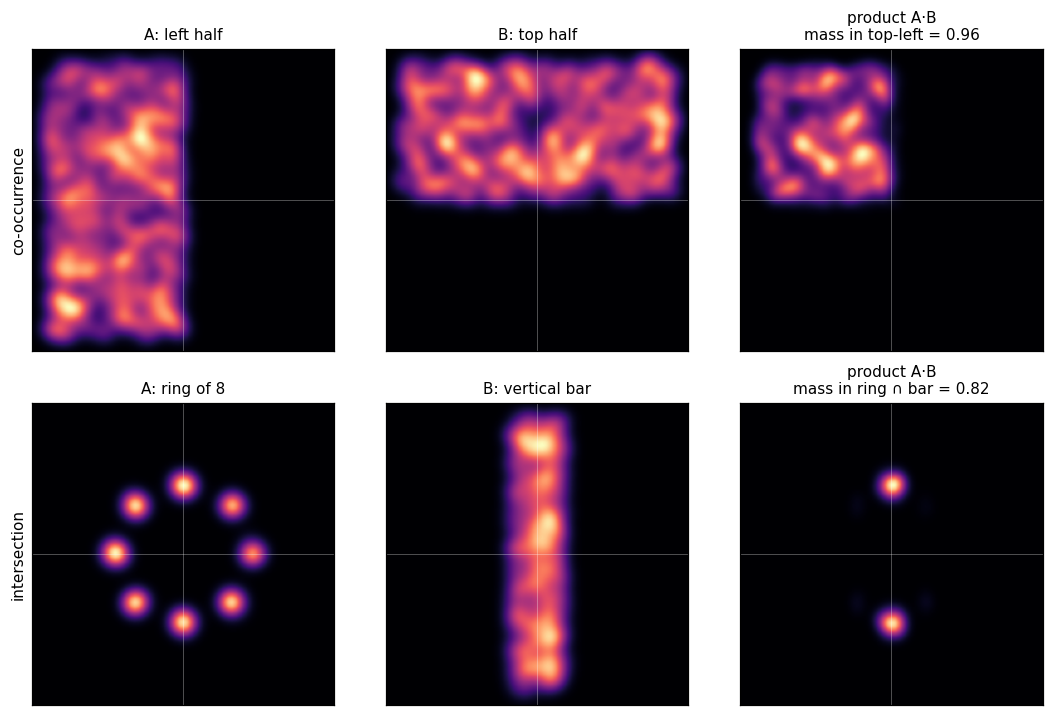

In [5]:
n = 2000
ring = lambda n: 0.5 * np.c_[np.cos(a := 2 * np.pi * rng.integers(0, 8, n) / 8), np.sin(a)] + 0.03 * rng.standard_normal((n, 2))
bar = lambda n: np.c_[rng.uniform(-0.2, 0.2, n), rng.uniform(-1, 1, n)]
left_half = lambda n: np.c_[rng.uniform(-1, 0, n), rng.uniform(-1, 1, n)]
top_half = lambda n: np.c_[rng.uniform(-1, 1, n), rng.uniform(0, 1, n)]
sub = lambda d: d[rng.choice(len(d), 600, replace=False)]   # subsample for speed on the grid

fig, ax = plt.subplots(2, 3, figsize=(10, 6.6))
for row, (fa, fb, na, nb_, region, rname) in enumerate([
        (left_half, top_half, "A: left half", "B: top half", TOP_LEFT, "top-left"),
        (ring, bar, "A: ring of 8", "B: vertical bar", (np.abs(X1) < 0.2) & (np.abs(np.hypot(X1, X2) - 0.5) < 0.1), "ring ∩ bar")]):
    lpA, lpB = ideal_expert(sub(fa(n)), 0.06), ideal_expert(sub(fb(n)), 0.06)
    show(ax[row, 0], density(lpA), na, region=None)
    show(ax[row, 1], density(lpB), nb_, region=None)
    prod = density(lpA + lpB)
    show(ax[row, 2], prod, f"product A·B\nmass in {rname} = {mass(prod, region):.2f}")
ax[0, 0].set_ylabel("co-occurrence"); ax[1, 0].set_ylabel("intersection")
plt.tight_layout()

### 4b. Contention: where a chimera comes from

Read the two coordinates as **two slots in an image**. A cat is the value $-0.5$ in some slot, and a dog is $+0.5$ in some slot. The other slot holds anything.

- **Centred training data**: every cat image has its cat in slot 1, and so does every dog image. Both experts constrain the same slot, so the product is a product over the same variables where a partition was meant. Its mass sits at $x_1 \approx 0$, a value that is neither cat nor dog. **That is the chimera.** For Gaussians the arithmetic is exact: $\mathcal{N}(-0.5, s^2)\,\mathcal{N}(+0.5, s^2) \propto \mathcal{N}(0, s^2/2)$.
- **Position-varied training data**: each object appears in either slot. The product now has modes at $(-0.5, +0.5)$ and $(+0.5, -0.5)$, one object per slot, both intact. **The same product operator produces co-occurrence.**

The numbers: "co-occurrence" is the mass where one slot is within 0.15 of $-0.5$ and the other within 0.15 of $+0.5$. "Chimera" is the mass where neither slot is within 0.15 of either object.

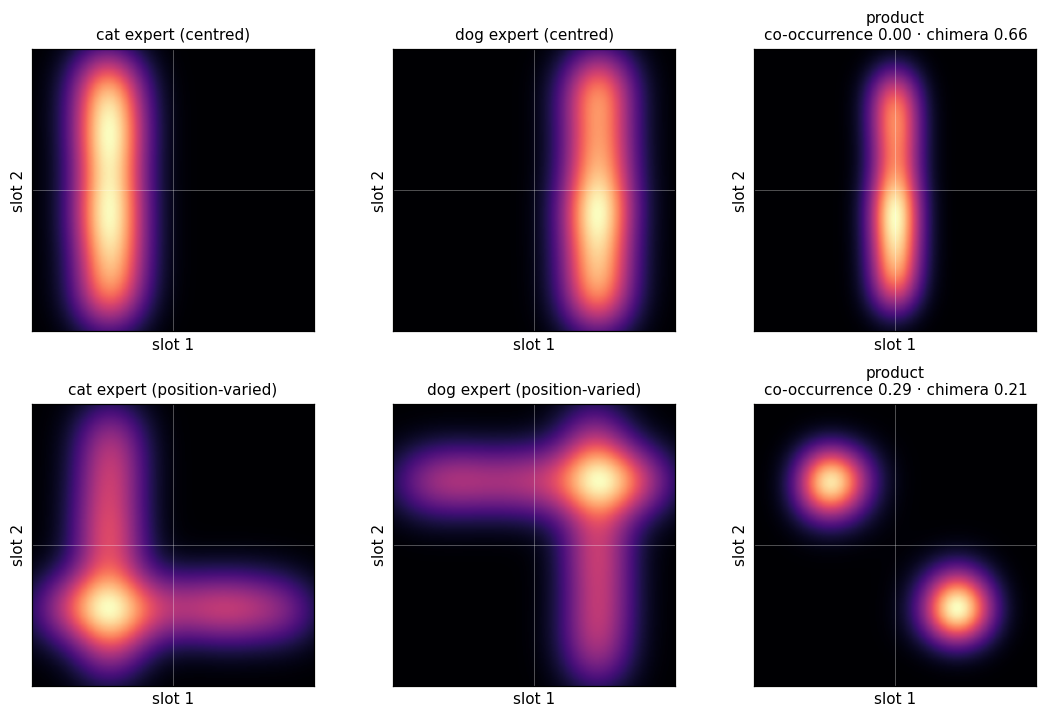

In [6]:
def obj(v, n, varied):
    o = v + 0.05 * rng.standard_normal(n); other = rng.uniform(-1, 1, n)
    swap = (rng.random(n) < 0.5) if varied else np.zeros(n, bool)
    return np.where(swap[:, None], np.c_[other, o], np.c_[o, other])

near = lambda Z, v: np.abs(Z - v) < 0.15
CO = (near(X1, -.5) & near(X2, .5)) | (near(X1, .5) & near(X2, -.5))
CHIMERA = ~(near(X1, -.5) | near(X1, .5) | near(X2, -.5) | near(X2, .5))

fig, ax = plt.subplots(2, 3, figsize=(10, 6.6))
for row, varied in enumerate([False, True]):
    cat, dog = obj(-0.5, 600, varied), obj(0.5, 600, varied)
    lpc, lpd = ideal_expert(cat, 0.2), ideal_expert(dog, 0.2)
    show(ax[row, 0], density(lpc), f"cat expert ({'position-varied' if varied else 'centred'})", region=None)
    show(ax[row, 1], density(lpd), f"dog expert ({'position-varied' if varied else 'centred'})", region=None)
    prod = density(lpc + lpd)
    show(ax[row, 2], prod, f"product\nco-occurrence {mass(prod, CO):.2f} · chimera {mass(prod, CHIMERA):.2f}")
    for a in ax[row]: a.set_xlabel("slot 1"); a.set_ylabel("slot 2")
plt.tight_layout()

**Reading it.** The operator is the same in both rows. What changed is **whether each expert's training data showed its object in more than one place.** So contention comes from the data: experts that never saw their object off-centre both claim the centre. In images, this predicts that cat-dog chimeras get rarer as the training data varies object position. That prediction is checkable.

### 4c. Interaction: wet dog

B is rain: the top half, with any $x_1$. A is a dog. Inside the A∩B quadrant, A looks different: its $x_1$ shifts from $-0.5$ to $-0.8$ when B is present (the dog is wet). Everywhere else A sits at $x_1 \approx -0.5$.

Separately trained experts see the shifted version only through the overlap in their training sets. The dial is set at 0% and at 20%, and the number is the mean $x_1$ of the product's mass in the top half: $-0.8$ means the interaction was produced, and $-0.5$ means a dry dog in the rain.

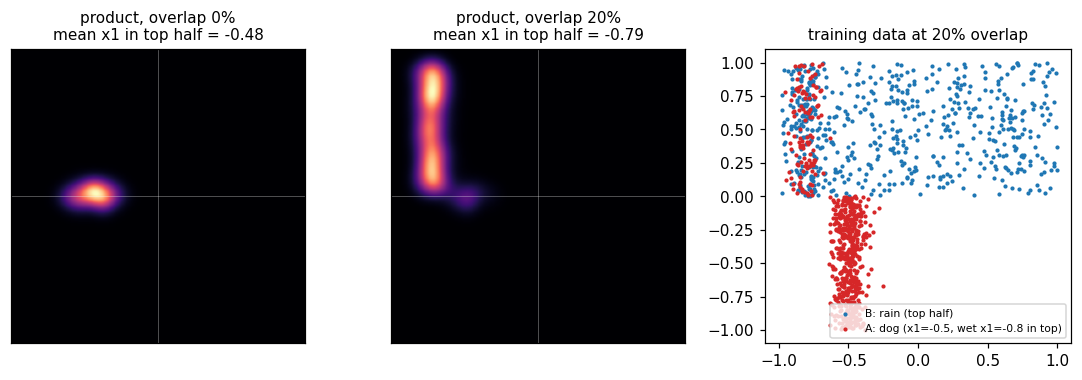

In [7]:
def interaction_sets(f, n=600):
    top = rng.random(n) < f
    a = np.c_[np.where(top, -0.8, -0.5) + 0.06 * rng.standard_normal(n),
              np.where(top, rng.uniform(0, 1, n), rng.uniform(-1, 0, n))]
    hid = rng.random(n) < f
    b = np.c_[np.where(hid, -0.8 + 0.06 * rng.standard_normal(n), rng.uniform(-1, 1, n)), rng.uniform(0, 1, n)]
    return a, b

fig, ax = plt.subplots(1, 3, figsize=(10, 3.4))
for a_, f in zip(ax[:2], [0.0, 0.2]):
    a, b = interaction_sets(f)
    prod = density(ideal_expert(a, 0.08) + ideal_expert(b, 0.08))
    top = X2 > 0
    mean_x1 = (prod * top * X1).sum() / (prod * top).sum()
    show(a_, prod, f"product, overlap {f:.0%}\nmean x1 in top half = {mean_x1:.2f}", region=None)
a, b = interaction_sets(0.2)
ax[2].scatter(*b.T, s=3, c="tab:blue", label="B: rain (top half)")
ax[2].scatter(*a.T, s=3, c="tab:red", label="A: dog (x1=-0.5, wet x1=-0.8 in top)")
ax[2].set_xlim(-L, L); ax[2].set_ylim(-L, L); ax[2].legend(fontsize=7, loc="lower right"); ax[2].set_title("training data at 20% overlap")
plt.tight_layout()

**Reading it.** At 0% overlap, neither expert has seen A under B's influence. The product puts its top-half mass near $x_1 = -0.5$, hugging the boundary $x_2 \approx 0$ where the dog expert's smoothed tail meets the rain: a dry dog at the edge of the rain. At 20% overlap, both experts hold some shifted points, and the product lands near $-0.8$. **The product found the interaction without any extra term, once the data contained it.** This is the evidence behind `break 7`: interaction may be intersection plus a data condition, rather than a third operator.

## What this notebook cannot show

- **Nothing here was sampled.** Every product is exact on the grid. A real sampler (reverse diffusion or annealed MCMC) adds its own error, and that is claim 4.
- **The experts are ideal.** A trained network extrapolates differently from Gaussian smoothing, and on images that extrapolation is the whole hope of claim 2. These figures show what the data permits, and say nothing about what a network invents.
- **Two dimensions only.** "Slots" and "regions" are single coordinates here. Pixels in an image are not independent coordinates, and an object's region is not fixed.